# CV Lab 09 – Object Detection (YOLO / SSD / RetinaNet) & Real-Time Pose Estimation

**How to use on Google Colab**
1. `Runtime → Change runtime type → T4 GPU` (CPU works too, just slower).
2. Run the cells top to bottom. When a cell uses the webcam, **allow camera access** in the browser.
3. No webcam? Set `USE_WEBCAM = False` in the setup cell – sample images are used instead.

| Task | Section |
|---|---|
| 1 | YOLO live webcam detection of lab assets |
| 2 | YOLOv3 vs SSD vs RetinaNet with boxes / labels / confidence |
| 3 | FPS, confidence per class, model size, inference time |
| 4 | Discussion: real-time, small objects, CPU-only |
| 5 | Real-time pose estimation with skeleton + joint angles |

## 0. Setup & Webcam helpers

In [4]:
!pip -q install ultralytics

import os, json, time, base64
from collections import Counter, defaultdict
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from IPython.display import display, Javascript
from google.colab.output import eval_js
from ultralytics import YOLO
from ultralytics.utils import ASSETS          # sample images shipped with ultralytics

USE_WEBCAM = True                              # False -> use sample images instead of the camera
CONF       = 0.35                              # confidence threshold used for every model
DEVICE     = 'cuda:0' if torch.cuda.is_available() else 'cpu'
print('Running on:', DEVICE, '|', torch.cuda.get_device_name(0) if DEVICE != 'cpu' else 'CPU only')

Running on: cuda:0 | Tesla T4


In [5]:
# ---- Browser webcam streaming helpers (JS <-> Python) -------------------------------------------
_JS = '''
var box=null, video=null, canvas=null, imgEl=null, labelEl=null, stream=null;
async function setupCam() {
  if (box) return;
  box = document.createElement('div');
  labelEl = document.createElement('div');
  labelEl.style.cssText = 'font:13px monospace;white-space:pre;padding:4px;min-height:20px';
  imgEl = document.createElement('img');
  imgEl.style.maxWidth = '100%';
  video = document.createElement('video');
  video.style.cssText = 'position:absolute;opacity:0;width:2px;height:2px';
  video.setAttribute('playsinline', ''); video.muted = true;
  box.appendChild(labelEl); box.appendChild(imgEl); box.appendChild(video);
  document.body.appendChild(box);
  stream = await navigator.mediaDevices.getUserMedia({video: {width: 640, height: 480}});
  video.srcObject = stream;
  await video.play();
  canvas = document.createElement('canvas'); canvas.width = 640; canvas.height = 480;
  google.colab.output.setIframeHeight(document.documentElement.scrollHeight + 520, true);
}
async function grab(label, overlayB64) {
  await setupCam();
  labelEl.textContent = label;
  if (overlayB64) imgEl.src = 'data:image/jpeg;base64,' + overlayB64;
  canvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
  return canvas.toDataURL('image/jpeg', 0.8);
}
function stopCam() {
  if (stream) stream.getTracks().forEach(t => t.stop());
  if (box) box.remove();
  box = null; stream = null;
}
'''

def _decode(data_url):
    if not data_url: return None
    buf = base64.b64decode(data_url.split(',')[1])
    return cv2.imdecode(np.frombuffer(buf, np.uint8), cv2.IMREAD_COLOR)

def run_live(process_fn, seconds=30):
    # Streams the webcam. process_fn(frame_bgr) -> (annotated_bgr, label_text).
    # Raise StopIteration inside process_fn to stop early. Returns end-to-end FPS.
    display(Javascript(_JS))
    t0, n, overlay, label = time.time(), 0, '', 'starting camera...'
    try:
        while time.time() - t0 < seconds:
            frame = _decode(eval_js(f'grab({json.dumps(label)}, "{overlay}")'))
            if frame is None: break
            out, label = process_fn(frame)
            ok, buf = cv2.imencode('.jpg', out, [cv2.IMWRITE_JPEG_QUALITY, 70])
            overlay = base64.b64encode(buf).decode()
            n += 1
    except StopIteration:
        pass
    finally:
        eval_js('stopCam()')
    return n / max(time.time() - t0, 1e-9)

def capture_frames(n=30, gap=0.3, countdown=5):
    # Grab n frames from the webcam (so every model is benchmarked on identical input).
    frames, st = [], {'t0': None, 'last': 0}
    def proc(frame):
        now = time.time()
        st['t0'] = st['t0'] or now
        left = countdown - (now - st['t0'])
        if left > 0: return frame, f'Place your lab assets in view... starting in {left:.0f}s'
        if now - st['last'] >= gap:
            frames.append(frame.copy()); st['last'] = now
        if len(frames) >= n: raise StopIteration
        return frame, f'Capturing {len(frames)}/{n}'
    run_live(proc, seconds=countdown + n * gap + 40)
    return frames

def sample_frames(n=30):
    imgs = [cv2.resize(cv2.imread(str(ASSETS / f)), (640, 480)) for f in ('bus.jpg', 'zidane.jpg')]
    return [imgs[i % len(imgs)].copy() for i in range(n)]

def show(img_bgr, title='', size=(8, 6)):
    plt.figure(figsize=size); plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.title(title); plt.show()

## Task 1 – YOLO live webcam detection of lab assets

YOLOv8n (pre-trained on COCO) already recognises many typical lab assets: `laptop, tv (monitor), keyboard, mouse, cell phone, bottle, cup, chair, book, backpack, scissors, remote, clock ...`.
Hold your items in front of the camera – the stream runs for `SECONDS` seconds.

In [6]:
SECONDS = 40
yolo_live = YOLO('yolov8n.pt')          # try 'yolov8s.pt' for better accuracy
print('Classes the model knows:', len(yolo_live.names))

def yolo_proc(frame):
    t = time.perf_counter()
    r = yolo_live.predict(frame, conf=CONF, device=DEVICE, verbose=False)[0]
    out = r.plot()                                           # boxes + labels + confidence
    fps = 1 / (time.perf_counter() - t)
    counts = Counter(yolo_live.names[int(c)] for c in r.boxes.cls)
    txt = ', '.join(f'{k} x{v}' for k, v in counts.items()) or 'nothing detected'
    return out, f'YOLOv8n | model FPS: {fps:5.1f} | {txt}'

if USE_WEBCAM:
    print('pipeline FPS (incl. browser transfer): %.1f' % run_live(yolo_proc, SECONDS))
else:
    out, lbl = yolo_proc(sample_frames(1)[0]); show(out, lbl)

Classes the model knows: 80


<IPython.core.display.Javascript object>

pipeline FPS (incl. browser transfer): 0.2


**Optional – detect *your own* lab assets that are not in COCO** (e.g. oscilloscope, multimeter, breadboard):
label ~100-200 photos (Roboflow / LabelImg), export in YOLO format, then fine-tune:
```python
# model = YOLO('yolov8n.pt')
# model.train(data='/content/lab_assets/data.yaml', epochs=50, imgsz=640)
# yolo_live = YOLO('runs/detect/train/weights/best.pt')   # and re-run the cell above
```

## Task 2 – Implement YOLOv3, SSD and RetinaNet on a common input

All models are pre-trained on COCO (80 classes):

| Model | Source |
|---|---|
| **YOLOv3** | Ultralytics `yolov3u.pt` |
| **SSD** | torchvision `ssd300_vgg16` |
| **RetinaNet** | torchvision `retinanet_resnet50_fpn` |
| *(bonus)* SSDLite-MobileNetV3, YOLOv8n | lightweight references for the CPU discussion |

First we collect one **common set of frames** (webcam or samples) so the comparison is fair.

<IPython.core.display.Javascript object>

30 frames of shape (480, 640, 3)


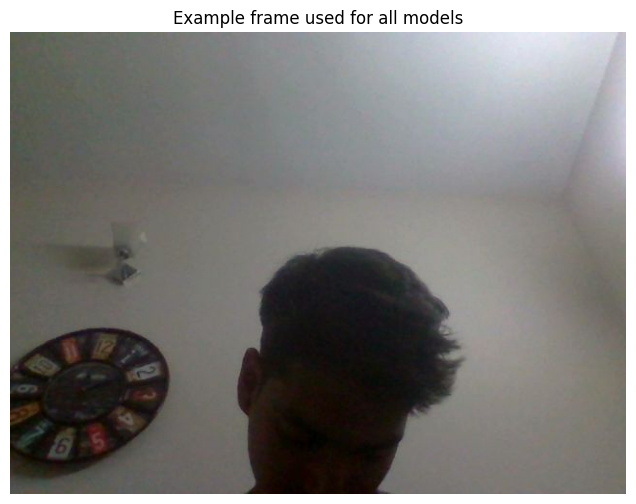

In [7]:
N_FRAMES = 30
FRAMES = capture_frames(N_FRAMES) if USE_WEBCAM else sample_frames(N_FRAMES)
print(len(FRAMES), 'frames of shape', FRAMES[0].shape)
show(FRAMES[len(FRAMES)//2], 'Example frame used for all models')

In [8]:
from torchvision.models.detection import (
    ssd300_vgg16, SSD300_VGG16_Weights,
    retinanet_resnet50_fpn, RetinaNet_ResNet50_FPN_Weights,
    ssdlite320_mobilenet_v3_large, SSDLite320_MobileNet_V3_Large_Weights)

class TVDetector:
    # torchvision detector with a common interface
    def __init__(self, name, ctor, weights_enum):
        self.name, self.device = name, 'cpu'
        w = weights_enum.DEFAULT
        self.classes = w.meta['categories']
        self.model = ctor(weights=w, score_thresh=CONF).eval()
        self.params = sum(p.numel() for p in self.model.parameters())
    def to(self, device):
        self.device = device; self.model.to(device); return self
    @torch.no_grad()
    def detect(self, bgr):
        x = torch.from_numpy(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)).permute(2, 0, 1).float().div(255).to(self.device)
        out = self.model([x])[0]
        if self.device.startswith('cuda'): torch.cuda.synchronize()
        res = []
        for b, l, s in zip(out['boxes'].cpu().numpy(), out['labels'].cpu().numpy(), out['scores'].cpu().numpy()):
            name = self.classes[int(l)]
            if s >= CONF and name != 'N/A':
                res.append(dict(box=b, label=name, score=float(s)))
        return res

class YOLODetector:
    def __init__(self, name, weights):
        self.name, self.weights, self.device = name, weights, 'cpu'
        self.m = YOLO(weights)
        self.params = sum(p.numel() for p in self.m.model.parameters())
    def to(self, device):
        self.device = device; self.m = YOLO(self.weights); return self   # fresh predictor for the new device
    def detect(self, bgr):
        r = self.m.predict(bgr, conf=CONF, device=self.device, verbose=False)[0]
        return [dict(box=b, label=self.m.names[int(c)], score=float(s))
                for b, c, s in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy(), r.boxes.conf.cpu().numpy())]

detectors = {
    'YOLOv3':        YOLODetector('YOLOv3', 'yolov3u.pt'),
    'SSD300-VGG16':  TVDetector('SSD300-VGG16', ssd300_vgg16, SSD300_VGG16_Weights),
    'RetinaNet-R50': TVDetector('RetinaNet-R50', retinanet_resnet50_fpn, RetinaNet_ResNet50_FPN_Weights),
    'SSDLite-MBv3':  TVDetector('SSDLite-MBv3', ssdlite320_mobilenet_v3_large, SSDLite320_MobileNet_V3_Large_Weights),
    'YOLOv8n':       YOLODetector('YOLOv8n', 'yolov8n.pt'),
}
for d in detectors.values(): print(f'{d.name:15s} params = {d.params/1e6:6.1f} M')

Downloading: "https://download.pytorch.org/models/ssd300_vgg16_coco-b556d3b4.pth" to /root/.cache/torch/hub/checkpoints/ssd300_vgg16_coco-b556d3b4.pth


100%|██████████| 136M/136M [00:00<00:00, 170MB/s]


Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_coco-eeacb38b.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_coco-eeacb38b.pth


100%|██████████| 130M/130M [00:00<00:00, 179MB/s]


Downloading: "https://download.pytorch.org/models/ssdlite320_mobilenet_v3_large_coco-a79551df.pth" to /root/.cache/torch/hub/checkpoints/ssdlite320_mobilenet_v3_large_coco-a79551df.pth


100%|██████████| 13.4M/13.4M [00:00<00:00, 178MB/s]

YOLOv3          params =  103.8 M
SSD300-VGG16    params =   35.6 M
RetinaNet-R50   params =   34.0 M
SSDLite-MBv3    params =    3.4 M
YOLOv8n         params =    3.2 M


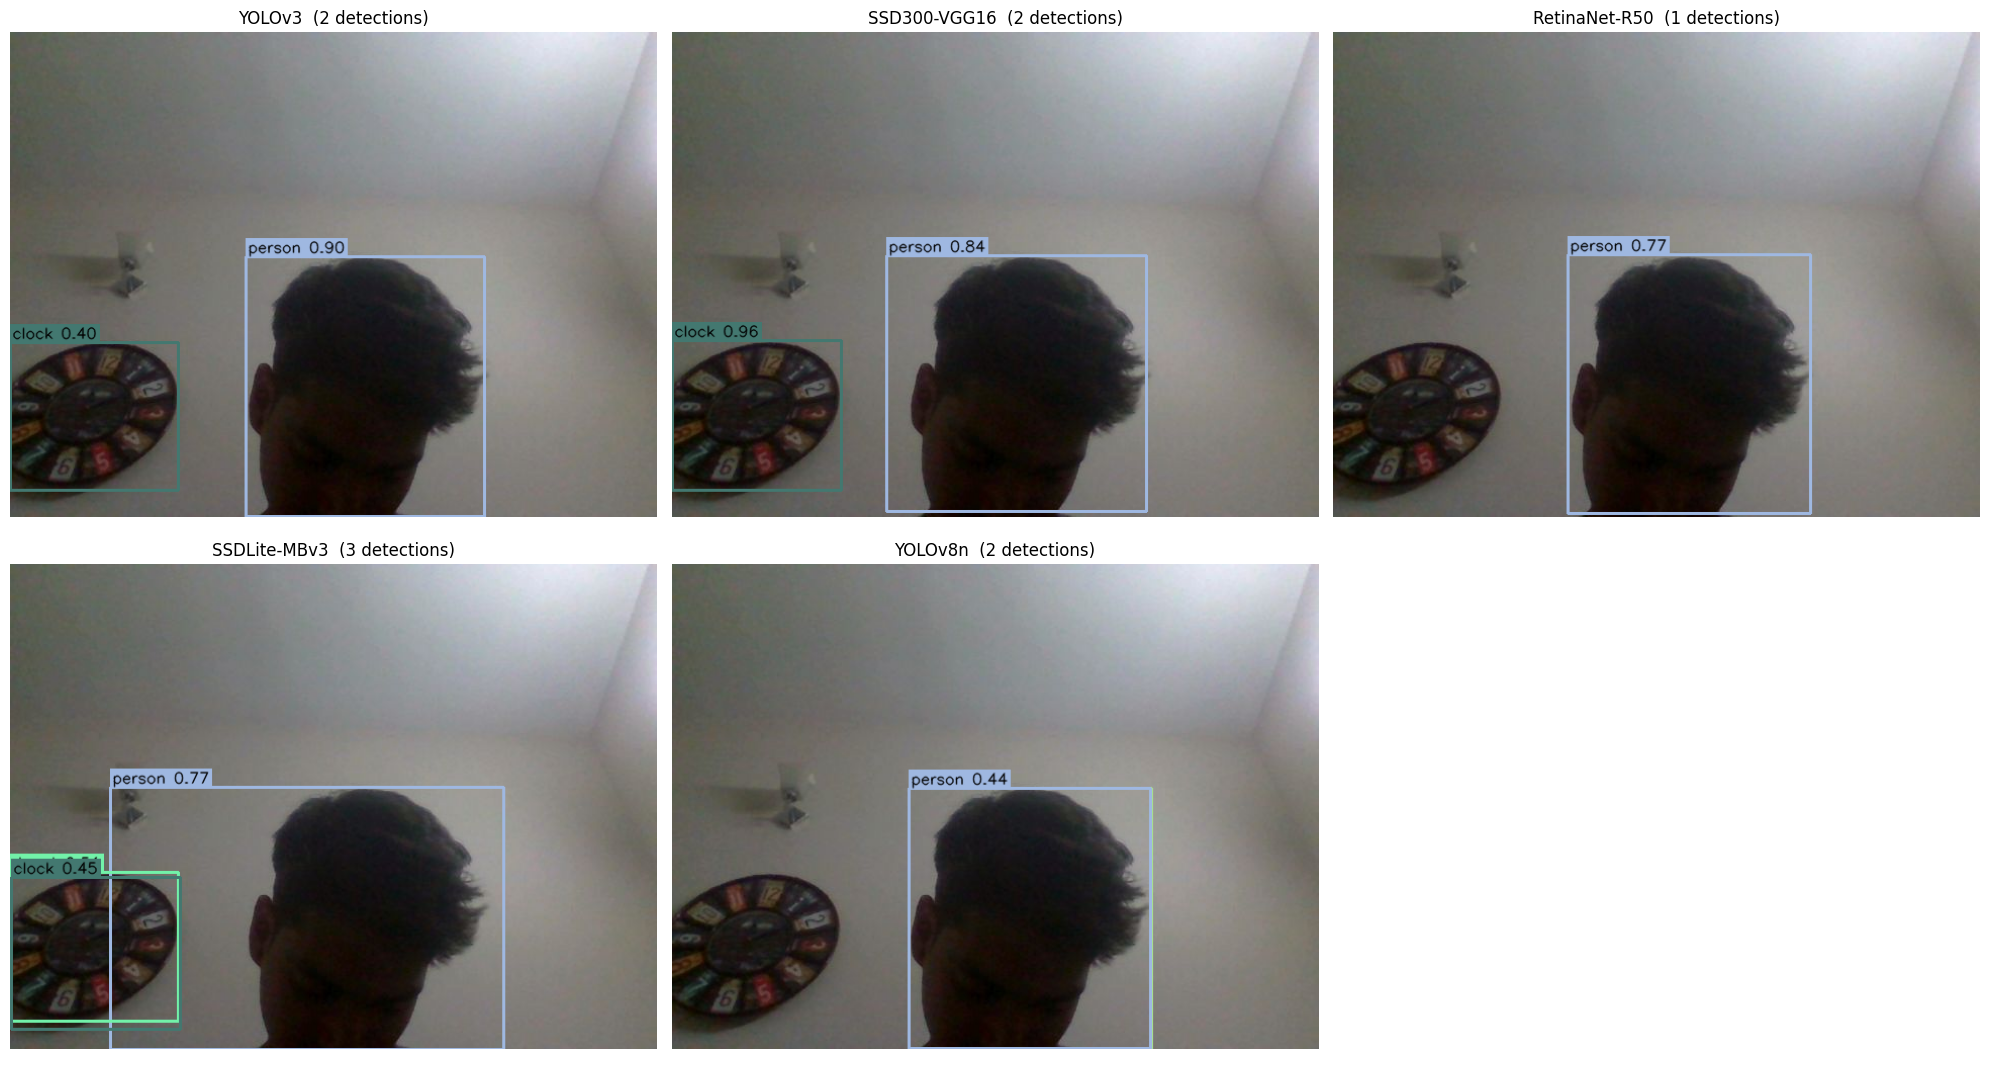

In [9]:
# ---- Draw bounding boxes, class labels and confidence scores ----------------------------------
rng = np.random.default_rng(0)
COLORS = {}
def draw(img, dets):
    out = img.copy()
    for d in dets:
        c = COLORS.setdefault(d['label'], tuple(int(v) for v in rng.integers(60, 255, 3)))
        x1, y1, x2, y2 = map(int, d['box'])
        cv2.rectangle(out, (x1, y1), (x2, y2), c, 2)
        txt = f"{d['label']} {d['score']:.2f}"
        (tw, th), _ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
        cv2.rectangle(out, (x1, y1 - th - 6), (x1 + tw + 4, y1), c, -1)
        cv2.putText(out, txt, (x1 + 2, y1 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 1, cv2.LINE_AA)
    return out

test_frame = FRAMES[len(FRAMES) // 2]
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
for ax, (name, det) in zip(axes.ravel(), detectors.items()):
    det.to(DEVICE); det.detect(test_frame)                       # warm-up
    dets = det.detect(test_frame)
    ax.imshow(cv2.cvtColor(draw(test_frame, dets), cv2.COLOR_BGR2RGB)); ax.axis('off')
    ax.set_title(f'{name}  ({len(dets)} detections)')
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()

### (Optional) Run any model live on the webcam

In [10]:
MODEL_TO_RUN = 'RetinaNet-R50'     # 'YOLOv3' | 'SSD300-VGG16' | 'RetinaNet-R50' | 'SSDLite-MBv3' | 'YOLOv8n'
SECONDS = 30
det = detectors[MODEL_TO_RUN].to(DEVICE)

def live_proc(frame):
    t = time.perf_counter(); dets = det.detect(frame); dt = time.perf_counter() - t
    return draw(frame, dets), f'{det.name} | {1/dt:5.1f} FPS | {dt*1000:6.1f} ms | {len(dets)} objects'

if USE_WEBCAM: run_live(live_proc, SECONDS)

<IPython.core.display.Javascript object>

## Task 3 – Measure & Record

For every model (on **GPU and CPU**) we record:
* **Detection speed (FPS)** and **inference time per frame** (mean ± std, after warm-up)
* **Model size** (parameters and fp32 size in MB)
* **Confidence scores** overall and **per object class**
* **Small-object performance** – detections whose box area is below `SMALL_AREA` pixels²

In [11]:
SMALL_AREA = 64 * 64          # boxes smaller than this count as "small objects" (COCO uses 32*32 for 640px+ images)
N_CPU      = 15               # use fewer frames on CPU (slow models)
devices    = (['cpu'] + ([DEVICE] if DEVICE != 'cpu' else []))

def benchmark(det, frames, device, warmup=2):
    det.to(device)
    for f in frames[:warmup]: det.detect(f)
    times, dets = [], []
    for f in frames:
        t = time.perf_counter(); d = det.detect(f); times.append(time.perf_counter() - t); dets.append(d)
    return np.array(times), dets

rows, records = [], []
for dev in devices:
    frames = FRAMES[:N_CPU] if dev == 'cpu' else FRAMES
    for name, det in detectors.items():
        t, dets = benchmark(det, frames, dev)
        flat = [d for fr in dets for d in fr]
        for d in flat:
            x1, y1, x2, y2 = d['box']
            records.append(dict(model=name, device=dev, label=d['label'], score=d['score'], area=(x2 - x1) * (y2 - y1)))
        small = [d for d in flat if (d['box'][2] - d['box'][0]) * (d['box'][3] - d['box'][1]) < SMALL_AREA]
        rows.append({
            'Model': name, 'Device': 'GPU' if dev != 'cpu' else 'CPU',
            'Inference (ms)': t.mean() * 1000, 'Std (ms)': t.std() * 1000, 'FPS': 1 / t.mean(),
            'Params (M)': det.params / 1e6, 'Size fp32 (MB)': det.params * 4 / 1e6,
            'Dets / frame': len(flat) / len(frames),
            'Mean conf': np.mean([d['score'] for d in flat]) if flat else 0,
            'Small obj / frame': len(small) / len(frames),
            'Small mean conf': np.mean([d['score'] for d in small]) if small else 0})
        print(f'{dev:7s} {name:15s} {1/t.mean():6.1f} FPS')
    for det in detectors.values(): det.to('cpu')           # free GPU memory

results = pd.DataFrame(rows).round(3)
det_df  = pd.DataFrame(records)
display(results)

cpu     YOLOv3             0.4 FPS
cpu     SSD300-VGG16       1.0 FPS
cpu     RetinaNet-R50      0.2 FPS
cpu     SSDLite-MBv3      16.6 FPS
cpu     YOLOv8n           10.3 FPS
cuda:0  YOLOv3            16.9 FPS
cuda:0  SSD300-VGG16      24.0 FPS
cuda:0  RetinaNet-R50      7.6 FPS
cuda:0  SSDLite-MBv3      32.2 FPS
cuda:0  YOLOv8n          112.4 FPS


,Model,Device,Inference (ms),Std (ms),FPS,Params (M),Size fp32 (MB),Dets / frame,Mean conf,Small obj / frame,Small mean conf
0,YOLOv3,CPU,2228.313,364.542,0.449,103.754,415.017,1.600,0.745,0.0,0
1,SSD300-VGG16,CPU,955.535,133.085,1.047,35.642,142.567,2.000,0.863,0.0,0
2,RetinaNet-R50,CPU,5660.599,428.645,0.177,34.015,136.060,2.000,0.631,0.0,0
3,SSDLite-MBv3,CPU,60.204,1.958,16.610,3.440,13.760,2.133,0.647,0.0,0
4,YOLOv8n,CPU,97.109,4.213,10.298,3.157,12.629,1.000,0.629,0.0,0
5,YOLOv3,GPU,59.218,0.557,16.887,103.754,415.017,1.400,0.784,0.0,0
6,SSD300-VGG16,GPU,41.736,5.551,23.960,35.642,142.567,1.933,0.823,0.0,0
7,RetinaNet-R50,GPU,131.686,1.573,7.594,34.015,136.060,1.767,0.674,0.0,0
8,SSDLite-MBv3,GPU,31.092,2.960,32.162,3.440,13.760,2.233,0.658,0.0,0
9,YOLOv8n,GPU,8.899,1.515,112.371,3.157,12.629,1.033,0.687,0.0,0


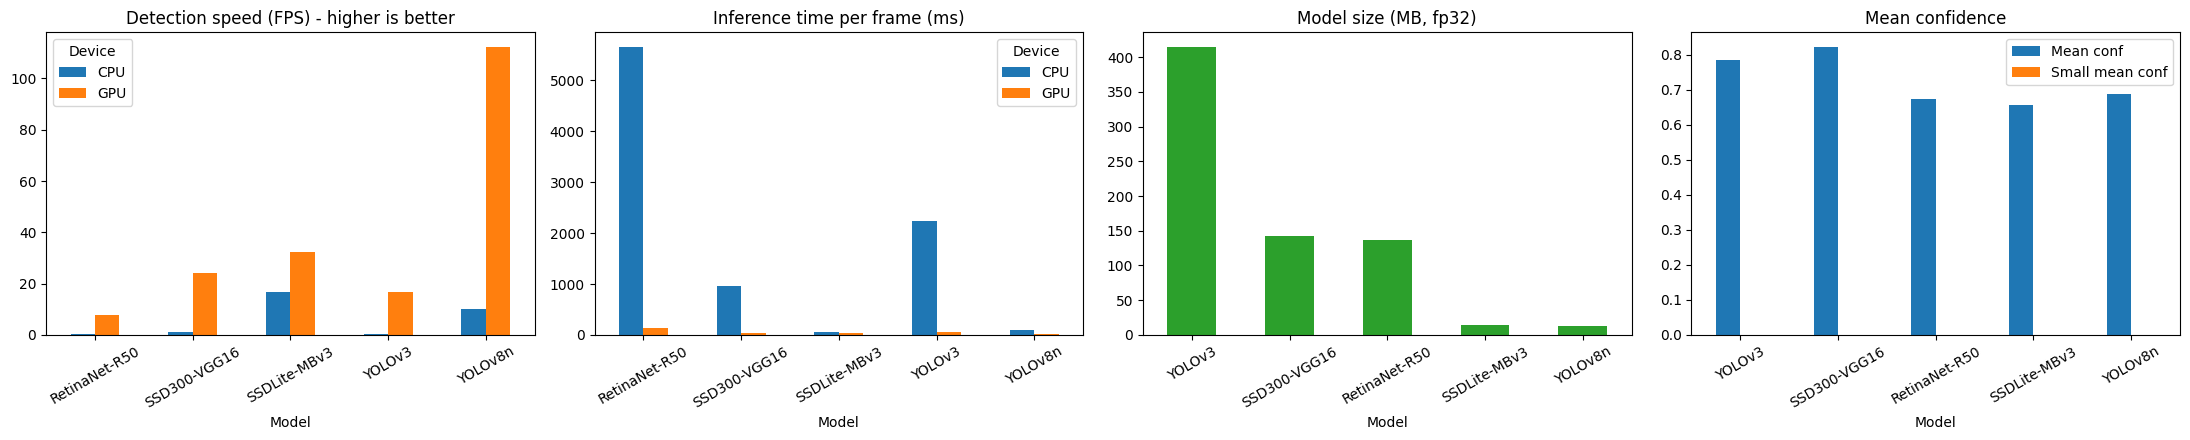

Mean confidence per object class (blank = model did not detect that class):


model,RetinaNet-R50,SSD300-VGG16,SSDLite-MBv3,YOLOv3,YOLOv8n
label,,,,,
cat,0.47,-,-,-,-
clock,0.39,0.79,0.56,0.49,-
dog,0.36,-,-,-,0.54
donut,0.36,-,0.54,-,-
mouse,0.41,-,-,-,-
person,0.87,0.86,0.77,0.90,0.69


In [12]:
# ---- Charts ----------------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
results.pivot(index='Model', columns='Device', values='FPS').plot.bar(ax=axes[0], title='Detection speed (FPS) - higher is better', rot=30)
results.pivot(index='Model', columns='Device', values='Inference (ms)').plot.bar(ax=axes[1], title='Inference time per frame (ms)', rot=30)
results[results.Device == results.Device.iloc[-1]].set_index('Model')['Size fp32 (MB)'].plot.bar(ax=axes[2], title='Model size (MB, fp32)', color='tab:green', rot=30)
results[results.Device == results.Device.iloc[-1]].set_index('Model')[['Mean conf', 'Small mean conf']].plot.bar(ax=axes[3], title='Mean confidence', rot=30)
plt.tight_layout(); plt.show()

# ---- Confidence per object type ---------------------------------------------------------------------
if len(det_df):
    pivot = det_df[det_df.device == det_df.device.iloc[-1]].pivot_table(index='label', columns='model', values='score', aggfunc='mean').round(2)
    print('Mean confidence per object class (blank = model did not detect that class):')
    display(pivot.style.background_gradient(cmap='YlGn', axis=None).format('{:.2f}', na_rep='-'))

## Task 4 – Which model performs best?
The cell below picks winners **from your measured numbers**; the table underneath explains why.

In [13]:
gpu_or_best = results.Device.iloc[-1]
r_all = results[results.Device == gpu_or_best]
r_cpu = results[results.Device == 'CPU']
main  = ['YOLOv3', 'SSD300-VGG16', 'RetinaNet-R50']            # the three required models

print(f"Real-time detection   (highest FPS on {gpu_or_best})   : {r_all.loc[r_all.FPS.idxmax(), 'Model']}  ({r_all.FPS.max():.1f} FPS)")
rm = r_all[r_all.Model.isin(main)]
print(f"   ... among the 3 required models                    : {rm.loc[rm.FPS.idxmax(), 'Model']}  ({rm.FPS.max():.1f} FPS)")
if (r_all['Small obj / frame'] > 0).any():
    s = r_all[r_all.Model.isin(main)].sort_values(['Small obj / frame', 'Small mean conf'], ascending=False).iloc[0]
    print(f"Small-object recognition (most small detections)      : {s.Model}  ({s['Small obj / frame']:.1f} small objs/frame, conf {s['Small mean conf']:.2f})")
else:
    print('Small-object recognition: no small objects in your frames - hold smaller items farther away and re-run Task 2/3.')
print(f"CPU-only / resource-limited (highest CPU FPS)         : {r_cpu.loc[r_cpu.FPS.idxmax(), 'Model']}  ({r_cpu.FPS.max():.1f} FPS)")
print(f"Smallest model                                        : {r_all.loc[r_all['Size fp32 (MB)'].idxmin(), 'Model']}  ({r_all['Size fp32 (MB)'].min():.1f} MB)")

Real-time detection   (highest FPS on GPU)   : YOLOv8n  (112.4 FPS)
   ... among the 3 required models                    : SSD300-VGG16  (24.0 FPS)
Small-object recognition: no small objects in your frames - hold smaller items farther away and re-run Task 2/3.
CPU-only / resource-limited (highest CPU FPS)         : SSDLite-MBv3  (16.6 FPS)
Smallest model                                        : YOLOv8n  (12.6 MB)


### Discussion (typical findings – confirm against your own table above)

| Criterion | Best choice | Reasoning |
|---|---|---|
| **Real-time detection** | **YOLO family** (YOLOv8n/YOLOv3) | Single-stage, one forward pass on a fixed-size input; highly optimised pipeline gives the highest FPS on GPU. SSD300 is also fast but less accurate; RetinaNet (ResNet-50-FPN, ~800 px input) is clearly slower. |
| **Small-object recognition** | **RetinaNet** | The Feature Pyramid Network provides high-resolution feature maps and the larger input size keeps small objects visible; focal loss handles the huge background/object imbalance. SSD300 (300×300 input, VGG features) loses small objects; YOLOv3 improved with 3-scale prediction but is below RetinaNet in accuracy per small object. |
| **Resource-limited / CPU-only** | **SSDLite-MobileNetV3 or YOLOv8n** | Tiny parameter count and low FLOPs → usable FPS on CPU. YOLOv3 (~100 M params), SSD300-VGG16 and RetinaNet are heavy (large model, slow CPU inference). |

**Trade-off summary:** speed ↔ accuracy. RetinaNet = most accurate but slowest; YOLO = best speed/accuracy balance; SSD300-VGG16 = mid-speed, weaker on small objects; lightweight variants (SSDLite, YOLOv8n) are the choice for embedded/CPU deployment.

## Task 5 – Real-Time Pose Estimation from Webcam

**Steps:** (a) access webcam with OpenCV/JS stream → (b) pose estimation on every frame (YOLOv8-pose, 17 COCO keypoints) → (c) draw skeleton and update live → (d) show joint angles (elbows, knees, shoulders).
The text above the video shows the **real-time coordinates and angles**.

In [14]:
pose = YOLO('yolov8n-pose.pt')
KP_NAMES = ['nose', 'L-eye', 'R-eye', 'L-ear', 'R-ear', 'L-shoulder', 'R-shoulder', 'L-elbow', 'R-elbow',
            'L-wrist', 'R-wrist', 'L-hip', 'R-hip', 'L-knee', 'R-knee', 'L-ankle', 'R-ankle']
SKELETON = [(5, 7), (7, 9), (6, 8), (8, 10), (5, 6), (5, 11), (6, 12), (11, 12),
            (11, 13), (13, 15), (12, 14), (14, 16), (0, 1), (0, 2), (1, 3), (2, 4)]
JOINT_ANGLES = {            # name: (point A, vertex B, point C) -> angle at B
    'L-elbow': (5, 7, 9), 'R-elbow': (6, 8, 10),
    'L-knee': (11, 13, 15), 'R-knee': (12, 14, 16),
    'L-shoulder': (7, 5, 11), 'R-shoulder': (8, 6, 12)}
KP_CONF = 0.5

def angle(a, b, c):
    # angle (degrees) at point b formed by a-b-c
    ba, bc = np.asarray(a) - np.asarray(b), np.asarray(c) - np.asarray(b)
    cos = np.dot(ba, bc) / (np.linalg.norm(ba) * np.linalg.norm(bc) + 1e-9)
    return float(np.degrees(np.arccos(np.clip(cos, -1, 1))))

history = defaultdict(list)      # joint -> [(time, angle)]
T0 = time.time()

def pose_proc(frame):
    t = time.perf_counter()
    r = pose.predict(frame, conf=0.4, device=DEVICE, verbose=False)[0]
    out, lines = frame.copy(), []
    if r.keypoints is not None and len(r.keypoints.xy) > 0:
        kp = r.keypoints.xy[0].cpu().numpy()
        kc = r.keypoints.conf[0].cpu().numpy() if r.keypoints.conf is not None else np.ones(17)
        ok = kc > KP_CONF
        for a, b in SKELETON:                                           # skeleton bones
            if ok[a] and ok[b]:
                cv2.line(out, tuple(kp[a].astype(int)), tuple(kp[b].astype(int)), (0, 255, 0), 3)
        for i, (x, y) in enumerate(kp):                                 # joints
            if ok[i]: cv2.circle(out, (int(x), int(y)), 5, (0, 0, 255), -1)
        for name, (a, b, c) in JOINT_ANGLES.items():                    # angles
            if ok[a] and ok[b] and ok[c]:
                ang = angle(kp[a], kp[b], kp[c]); history[name].append((time.time() - T0, ang))
                cv2.putText(out, f'{ang:.0f}', (int(kp[b][0]) + 8, int(kp[b][1]) - 8),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2, cv2.LINE_AA)
                lines.append(f'{name:<11} angle {ang:6.1f} deg   at ({kp[b][0]:4.0f},{kp[b][1]:4.0f})')
        for i in (0, 9, 10):                                            # nose + wrist coordinates
            if ok[i]: lines.append(f'{KP_NAMES[i]:<11} x={kp[i][0]:4.0f}  y={kp[i][1]:4.0f}')
    fps = 1 / (time.perf_counter() - t)
    return out, f'Pose FPS: {fps:5.1f}\n' + ('\n'.join(lines) if lines else 'no person detected')

SECONDS = 45
if USE_WEBCAM:
    history.clear(); T0 = time.time()
    run_live(pose_proc, SECONDS)
else:
    out, lbl = pose_proc(cv2.resize(cv2.imread(str(ASSETS / 'bus.jpg')), (640, 480))); print(lbl); show(out, 'Pose (sample image)')

<IPython.core.display.Javascript object>

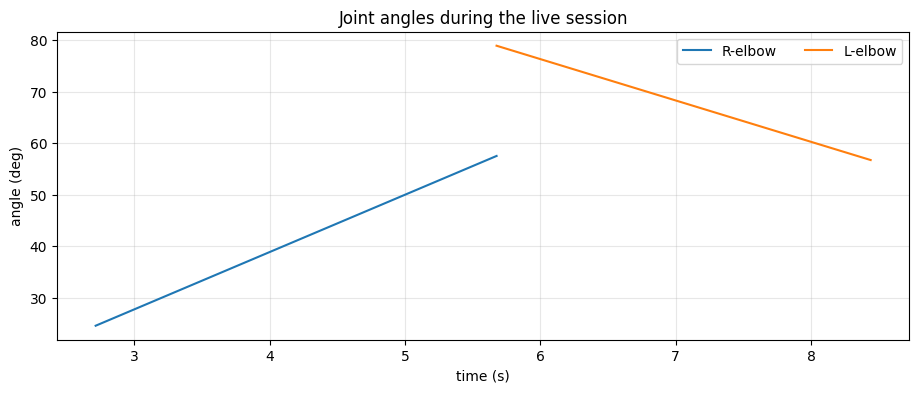

In [15]:
# ---- Plot the recorded joint angles over time ----------------------------------------------------
if history:
    plt.figure(figsize=(11, 4))
    for name, vals in history.items():
        t, a = zip(*vals); plt.plot(t, a, label=name)
    plt.xlabel('time (s)'); plt.ylabel('angle (deg)'); plt.title('Joint angles during the live session')
    plt.legend(ncol=3); plt.grid(alpha=.3); plt.show()
else:
    print('No angles recorded - make sure your upper body is visible to the camera.')

---
**Done.** Tip: keep the camera on only while a cell runs – each live cell stops and releases the webcam automatically when finished.